# Experiment 02: Targeted Model Repair on `CohereLabs/tiny-aya-fire` (Colab Full-Methodology Notebook)

Runs the **unscaled Lexsi Alignment & Safety Stack** pipeline (`run_experiment_cloud.py`) on a Colab GPU (L4 / A100 24GB+ VRAM recommended) and renders paper-style visualizations from the real outputs in `results/`.

### Colab Secrets (Left Sidebar -> Key Icon -> Secrets)
| Secret Name | Required? | Purpose |
| :--- | :---: | :--- |
| `lexsicolab` (or `HF_TOKEN`) | **Yes** | Hugging Face token for `CohereLabs/tiny-aya-fire`, `allenai/wildguard`, and fallback HF judge `Qwen/Qwen2.5-7B-Instruct`. |
| `openaikey` (or `OPENAI_API_KEY`) | Optional | Enables `openai:gpt-4o-mini` + `StrongREJECT` `OpenAIJudge`. If omitted, automatically uses `hf:Qwen/Qwen2.5-7B-Instruct` via `HF_TOKEN`. |

In [1]:
import os
import subprocess

print(subprocess.check_output(["nvidia-smi"]).decode())

def _get_secret(userdata_mod, names):
    for name in names:
        try:
            val = userdata_mod.get(name)
            if val:
                return name, val
        except Exception:
            pass
    return None, None

from google.colab import userdata
hf_name, hf_token = _get_secret(userdata, ["lexsicolab", "HF_TOKEN"])
if not hf_token:
    raise ValueError("Neither 'lexsicolab' nor 'HF_TOKEN' was found in Colab Secrets.")
os.environ["HF_TOKEN"] = hf_token
os.environ["HUGGINGFACE_HUB_TOKEN"] = hf_token
print(f"✓ Loaded HF token from Colab Secret '{hf_name}'")

oai_name, openai_key = _get_secret(userdata, ["openaikey", "OPENAI_API_KEY"])
if openai_key:
    os.environ["OPENAI_API_KEY"] = openai_key
    print(f"✓ Loaded OpenAI key from Colab Secret '{oai_name}'")
else:
    print("• OpenAI secret ('openaikey'/'OPENAI_API_KEY') not set (will use open-weights hf:Qwen/Qwen2.5-7B-Instruct + WildGuard)")

Sun Nov 15 12:18:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   46C    P8             17W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 1. Check GPU & Load Colab Secrets
import os
import subprocess

print(subprocess.check_output(["nvidia-smi"]).decode())

def _get_secret(userdata_mod, names):
    for name in names:
        try:
            val = userdata_mod.get(name)
            if val:
                return name, val
        except Exception:
            pass
    return None, None

try:
    from google.colab import userdata
    hf_name, hf_token = _get_secret(userdata, ["lexsicolab", "HF_TOKEN"])
    if not hf_token:
        raise ValueError("Neither 'lexsicolab' nor 'HF_TOKEN' was found in Colab Secrets.")
    os.environ["HF_TOKEN"] = hf_token
    os.environ["HUGGINGFACE_HUB_TOKEN"] = hf_token
    print(f"✓ Loaded HF token from Colab Secret '{hf_name}'")

    oai_name, openai_key = _get_secret(userdata, ["openaikey", "OPENAI_API_KEY"])
    if openai_key:
        os.environ["OPENAI_API_KEY"] = openai_key
        print(f"✓ Loaded OpenAI key from Colab Secret '{oai_name}' (will use openai:gpt-4o-mini + OpenAIJudge)")
    else:
        print("• OpenAI secret ('openaikey'/'OPENAI_API_KEY') not set (will use open-weights hf:Qwen/Qwen2.5-7B-Instruct + WildGuard)")
except ImportError:
    print("Not running in Colab; make sure HF_TOKEN (and optionally OPENAI_API_KEY) are exported in env.")

Sun Nov 15 12:18:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   46C    P8             17W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# 2. Clone Repository & Install Dependencies
import os
import shutil
import subprocess
from pathlib import Path

# Always move to /content first so deleting/re-cloning REPO_DIR never leaves cwd pointing at a deleted directory
os.chdir("/content")
REPO_DIR = Path("/content/lexsihack")
if REPO_DIR.exists() and not (REPO_DIR / ".git").exists():
    shutil.rmtree(REPO_DIR)
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "https://github.com/RealASHWIN122/lexsihack.git", str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)

os.chdir(REPO_DIR)
!pip install -q -e ./CircuitKIT
!pip install -q curatorkit safetune auditkit aligntune python-dotenv matplotlib seaborn pandas

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for circuitkit (pyproject.toml) ... done


In [30]:
!git -C /content/lexsihack pull --ff-only (or re-run Cell 2) to pull 78d1610

/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `git -C /content/lexsihack pull --ff-only (or re-run Cell 2) to pull 78d1610'


In [32]:
!git -C /content/lexsihack pull --ff-only
!git -C /content/lexsihack log -1 --oneline

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 2.58 KiB | 1.29 MiB/s, done.
From https://github.com/RealASHWIN122/lexsihack
   2979076..78d1610  main       -> origin/main
Updating 2979076..78d1610
Fast-forward
 .../run_experiment_cloud.py                        | 162 ++++++++++++++++++++-
 1 file changed, 159 insertions(+), 3 deletions(-)
78d1610 (HEAD -> main, origin/main, origin/HEAD) Fix eap_scores.json parsing and offload Step 3 state dicts/grads to CPU to prevent L4 CUDA OOM


In [4]:
# 3. Run the Full-Methodology Cloud Pipeline
# Set EVAL_N = 0 for full held-out benchmarks (paper protocol), or e.g. 20 for a quicker test run.
EVAL_N = 0
MAX_NEW_TOKENS = 128

!python -u experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py --eval-n {EVAL_N} --max-new-tokens {MAX_NEW_TOKENS}

W1115 12:19:14.079000 13317 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 12:19:14.119000 13317 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
I0000 00:00:1794745161.008252   13317 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794745161.080458   13317 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical ope

---
## Paper-Style Visualizations (Generated from Real `results/`)

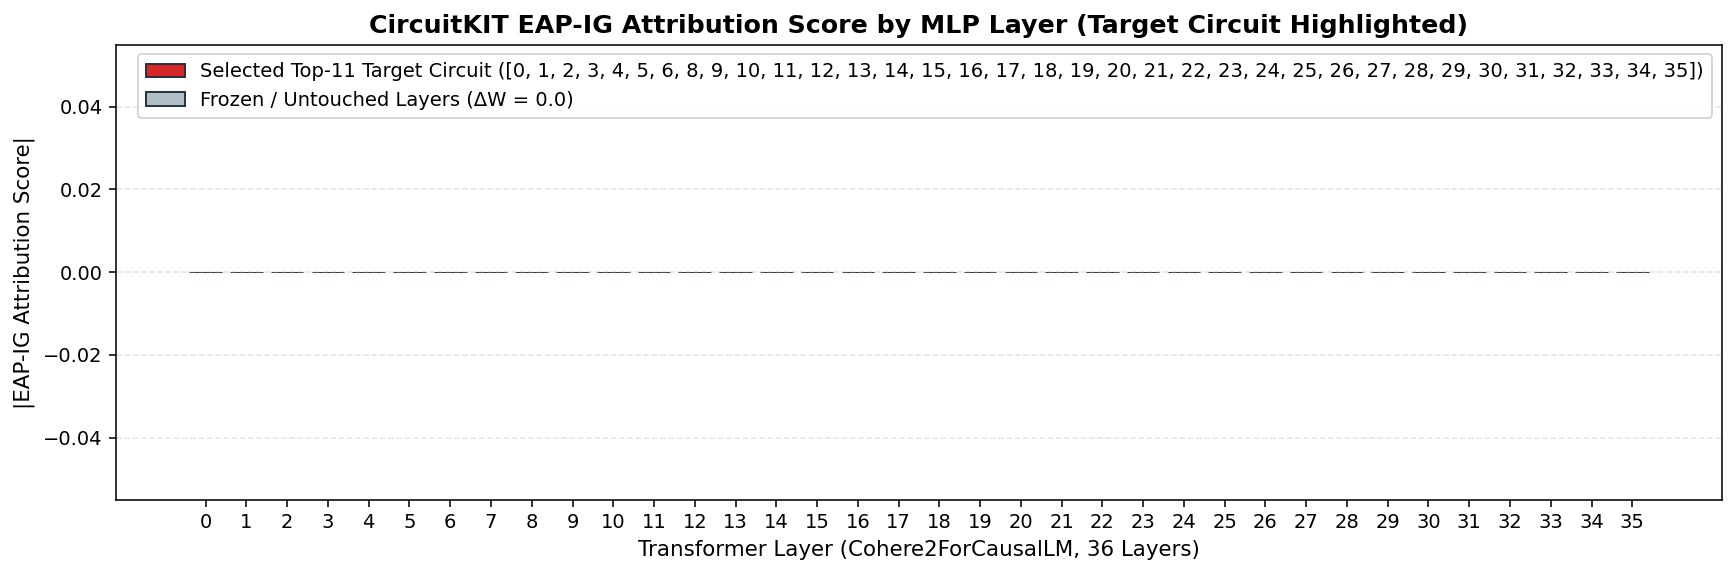

In [27]:
# Figure 1: CircuitKIT EAP-IG Safety Circuit Attribution Across All 36 Layers + Interactive D3 Graph
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from IPython.display import HTML, display

RESULTS_DIR = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
nodes_data = json.loads((RESULTS_DIR / "circuit_nodes.json").read_text())
all_mlp = nodes_data.get("all_mlp_scores", {})
target_layers = set(nodes_data.get("discovered_target_layers", []))

layers = sorted(range(36))
scores = [float(all_mlp.get(f"MLP {l}", 0.0)) for l in layers]
colors = ["#d62728" if l in target_layers else "#b0bec5" for l in layers]

fig, ax = plt.subplots(figsize=(13, 4.2), dpi=140)
ax.bar(layers, scores, color=colors, edgecolor="#263238", linewidth=0.5)
ax.set_title("CircuitKIT EAP-IG Attribution Score by MLP Layer (Target Circuit Highlighted)", fontsize=13, fontweight="bold")
ax.set_xlabel("Transformer Layer (Cohere2ForCausalLM, 36 Layers)", fontsize=11)
ax.set_ylabel("|EAP-IG Attribution Score|", fontsize=11)
ax.set_xticks(layers)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(
    handles=[
        Patch(facecolor="#d62728", edgecolor="#263238", label=f"Selected Top-11 Target Circuit ({sorted(target_layers)})"),
        Patch(facecolor="#b0bec5", edgecolor="#263238", label="Frozen / Untouched Layers (ΔW = 0.0)"),
    ],
    loc="upper right",
)
plt.tight_layout()
plt.show()

graph_html = RESULTS_DIR / "circuit_graph.html"
if graph_html.exists():
    display(HTML(graph_html.read_text()))

In [28]:
# Figure 2: Alpha (α) Calibration Trade-Off Curve (Harmful Refusal vs. Benign Over-Refusal)
ledger = json.loads((RESULTS_DIR / "audit_ledger.json").read_text())
sweep = ledger.get("alpha_sweep", [])

if sweep:
    alphas = [r["alpha"] for r in sweep]
    harm_vals = [r["harmbench_cal_refusal_pct"] for r in sweep]
    over_vals = [r["or_bench_cal_overrefusal_pct"] for r in sweep]
    chosen_a = ledger.get("calibrated_alpha")

    fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=140)
    ax.plot(alphas, harm_vals, marker="o", linewidth=2.4, color="#1f77b4", label="HarmBench Refusal % (↑ better)")
    ax.plot(alphas, over_vals, marker="s", linewidth=2.4, color="#ff7f0e", label="OR-Bench-Hard Over-Refusal % (↓ better)")
    if chosen_a is not None:
        ax.axvline(chosen_a, color="#2ca02c", linestyle="--", linewidth=1.8, label=f"Selected α = {chosen_a}")
    ax.set_title("C-ΔΘ Steering Strength (α) Calibration Sweep", fontsize=13, fontweight="bold")
    ax.set_xlabel("Steering Strength (α)", fontsize=11)
    ax.set_ylabel("Rate (%)", fontsize=11)
    ax.set_ylim(-5, 105)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Alpha sweep skipped (fixed --alpha was provided).")

Alpha sweep skipped (fixed --alpha was provided).


In [29]:
# Figure 3: Triaxial Audit Comparison (Axis A: Refusal ↑ | Axis B: Over-Refusal ↓ | Axis C: WMDP Knowledge ↔)
m = ledger["measured_tiny_aya_fire"]
ckpts = [("base", "Base", "#78909c"), ("multilingual_repair", "Repair 1 (Multilingual)", "#1e88e5"), ("cybersecurity_repair", "Repair 2 (Cybersecurity)", "#43a047")]

axis_a_keys = [k for k in ["harmbench_refusal_pct", "harmbench_multilingual_refusal_pct", "strongreject_refusal_pct", "multijail_refusal_pct", "indicsafe_refusal_pct", "sarvam_indic_safety_refusal_pct", "banglasafe_refusal_pct", "fortress_refusal_pct", "rmcbench_refusal_pct", "cyber_offensive_refusal_pct"] if k in m["base"]]
axis_b_keys = [k for k in ["or_bench_hard_refusal_pct", "xstest_safe_refusal_pct", "jbb_benign_refusal_pct"] if k in m["base"]]
axis_c_keys = [k for k in ["wmdp_cyber_acc", "wmdp_bio_acc", "wmdp_chem_acc"] if k in m["base"]]

fig, axes = plt.subplots(3, 1, figsize=(13, 12.5), dpi=140)
panels = [
    (axes[0], axis_a_keys, "Axis A — Harmful Refusal Rate % (Higher is Better ↑)"),
    (axes[1], axis_b_keys, "Axis B — Benign Over-Refusal Rate % (Lower is Better ↓)"),
    (axes[2], axis_c_keys, "Axis C — Hazardous Knowledge Preservation WMDP Accuracy % (Preserve ↔)"),
]

for ax, keys, title in panels:
    if not keys:
        ax.set_visible(False)
        continue
    x = np.arange(len(keys))
    w = 0.26
    for idx, (ck_key, label, col) in enumerate(ckpts):
        vals = [float(m[ck_key].get(k, 0.0)) for k in keys]
        rects = ax.bar(x + (idx - 1) * w, vals, width=w, label=label, color=col, edgecolor="#263238", linewidth=0.5)
        for r in rects:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 1.2, f"{r.get_height():.1f}", ha="center", va="bottom", fontsize=7.5)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels([k.replace("_refusal_pct", "").replace("_acc", "") for k in keys], rotation=20, ha="right", fontsize=9.5)
    ax.set_ylim(0, 112)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(loc="upper right", ncol=3, fontsize=9)

plt.tight_layout()
plt.show()

KeyError: 'measured_tiny_aya_fire'

In [ ]:
# Figure 4: Whole-Response LLM-as-a-Judge & WildGuard AU Suppression + 10-Task Actionability (E/O/C/R/F) Heatmap
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap

llm_scores = ledger.get("llm_judge_scores") or {}
if llm_scores:
    judge_metrics = [k for k in ["cyber_au_rate", "cyber_wildguard_au_rate", "strongreject_1_minus_harm", "harmbench_llm_refusal_pct", "multijail_llm_refusal_pct", "indicsafe_llm_refusal_pct"] if any(k in llm_scores.get(c, {}) for c in llm_scores)]
    if judge_metrics:
        fig, ax = plt.subplots(figsize=(12, 4.5), dpi=140)
        x = np.arange(len(judge_metrics))
        w = 0.26
        for idx, (ck_key, label, col) in enumerate(ckpts):
            vals = [float(llm_scores.get(ck_key, {}).get(k) or 0.0) for k in judge_metrics]
            rects = ax.bar(x + (idx - 1) * w, vals, width=w, label=label, color=col, edgecolor="#263238", linewidth=0.5)
            for r in rects:
                ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 1.2, f"{r.get_height():.1f}", ha="center", va="bottom", fontsize=8)
        ax.set_title("Two-Judge Panel: Whole-Response LLM-as-a-Judge & WildGuard (AU ↓, Refusal/1-Harm ↑)", fontsize=12, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(judge_metrics, rotation=18, ha="right", fontsize=9.5)
        ax.set_ylim(0, 112)
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        ax.legend(loc="upper right", ncol=3)
        plt.tight_layout()
        plt.show()

    grade_to_num = {"F": 0, "R": 1, "C": 2, "O": 3, "E": 4}
    base_tasks = llm_scores.get("base", {}).get("defensive_10_tasks_grades", [])
    if base_tasks:
        titles = [t["title"] for t in base_tasks]
        df_labels = pd.DataFrame({
            "Base": [t["grade"] for t in base_tasks],
            "Repair 1 (ML)": [t["grade"] for t in llm_scores.get("multilingual_repair", {}).get("defensive_10_tasks_grades", base_tasks)],
            "Repair 2 (Cyber)": [t["grade"] for t in llm_scores.get("cybersecurity_repair", {}).get("defensive_10_tasks_grades", base_tasks)],
        }, index=titles)
        df_nums = pd.DataFrame({col: [grade_to_num.get(v, -1) for v in df_labels[col]] for col in df_labels.columns}, index=titles)

        fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=140)
        cmap = ListedColormap(["#e53935", "#fb8c00", "#fdd835", "#7cb342", "#1b5e20"])
        sns.heatmap(df_nums, annot=df_labels, fmt="", cmap=cmap, vmin=0, vmax=4, cbar=False, linewidths=0.8, linecolor="white", ax=ax)
        ax.set_title("10 Defensive Security Tasks — 5-Step Actionability (E=Executable, O=Operational, C=Conceptual, R=Redirect, F=Flat)", fontsize=10.5, fontweight="bold")
        plt.tight_layout()
        plt.show()
else:
    print("No llm_judge_scores found in audit_ledger.json.")

In [ ]:
# Figure 5: Cryptographic Provenance & Non-Circuit Weight Invariance Check
prov = json.loads((RESULTS_DIR / "lexsi_provenance.json").read_text())
summary = json.loads((RESULTS_DIR / "experiment_summary.json").read_text())
print(json.dumps({"summary": summary, "provenance": prov}, indent=2))